## Practical 14: News Category Prediction

### Aim
Classify headlines into Sports, Business, Technology, Politics and Entertainment.

### Model
TF-IDF + Multinomial Logistic Regression

### Data
100 original teaching headlines: 20 per category, with no downloaded news text. Each headline is unique.

### Theory
TF-IDF represents unigram and bigram evidence. Logistic regression with the lbfgs solver optimizes multinomial softmax loss for the five-class task.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
Topic keywords are comparatively clear in this teaching corpus; production news can span multiple categories or change vocabulary.

In [ ]:
# Colab CPU runtime is sufficient. No external dataset download is needed.
%pip -q install 'scikit-learn>=1.5,<2' 'pandas>=2.2,<4' 'matplotlib>=3.8,<4'


In [1]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [2]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)
(DATA / 'news.csv').write_text('text,label\nFootball team wins championship after dramatic final,Sports\nCricket captain scores century in tournament victory,Sports\nTennis star reaches final after thrilling match,Sports\nOlympic runner sets record in sprint race,Sports\nBasketball team signs experienced coach for season,Sports\nHockey players prepare for international tournament,Sports\nFootball club announces new stadium training facilities,Sports\nSwimmer wins gold medal at national championships,Sports\nCricket league introduces revised match schedule,Sports\nTennis champion returns after injury recovery,Sports\nAthletics federation selects squad for world games,Sports\nBaseball team celebrates playoff victory at home,Sports\nCyclist takes lead in mountain stage race,Sports\nBadminton player wins first international title,Sports\nRugby squad prepares for difficult away match,Sports\nFootball goalkeeper saves penalty in cup final,Sports\nMarathon runners gather for annual city race,Sports\nVolleyball team secures place in regional finals,Sports\nBoxing champion defends title in close contest,Sports\nSports academy launches training camp for young athletes,Sports\nStock market rises as company profits beat forecasts,Business\nBank announces lower interest rates for business loans,Business\nRetail company reports strong quarterly sales growth,Business\nInvestors welcome merger between major financial firms,Business\nOil prices fall amid concerns about global demand,Business\nStartup raises funding to expand its operations,Business\nCentral bank reviews inflation and monetary policy,Business\nManufacturing company opens factory creating new jobs,Business\nCurrency markets react to economic growth figures,Business\nExport businesses seek relief from rising costs,Business\nShareholders approve new corporate investment plan,Business\nBanking sector reports increase in digital payments,Business\nRetail chain expands stores ahead of festive season,Business\nInsurance company announces improved annual earnings,Business\nInvestors shift funds as bond yields increase,Business\nSmall businesses report recovery in customer demand,Business\nTrade agreement aims to boost exports and investment,Business\nCompany shares decline after disappointing revenue report,Business\nEconomic survey shows growth in service industries,Business\nFinance ministry discusses tax incentives for businesses,Business\nSoftware company launches new artificial intelligence tool,Technology\nResearchers develop faster computer chip for mobile devices,Technology\nCybersecurity experts discover flaw in popular software,Technology\nNew smartphone offers improved battery and camera,Technology\nCloud computing platform adds data protection features,Technology\nScientists test robot designed for underwater exploration,Technology\nTechnology startup builds accessible virtual reality headset,Technology\nNew programming framework simplifies web application development,Technology\nArtificial intelligence system improves speech recognition accuracy,Technology\nSpace agency tests communication technology for satellites,Technology\nComputer engineers develop energy efficient processors,Technology\nSoftware update fixes security issues in messaging app,Technology\nResearchers demonstrate advances in quantum computing hardware,Technology\nNew wearable device monitors fitness with smart sensors,Technology\nInternet provider expands high speed fibre network,Technology\nRobotics team unveils automated warehouse machine,Technology\nTechnology firm releases open source machine learning library,Technology\nSmartphone manufacturer introduces foldable display design,Technology\nCybersecurity conference focuses on protecting digital identities,Technology\nDevelopers create software to detect manipulated images,Technology\nParliament debates new education bill during winter session,Politics\nGovernment announces reforms after cabinet meeting,Politics\nElection commission publishes schedule for national polls,Politics\nOpposition leaders demand debate on public spending,Politics\nPresident meets foreign minister for diplomatic talks,Politics\nVoters head to polls in closely contested election,Politics\nPolitical parties negotiate coalition after election results,Politics\nCabinet approves proposal for local government reform,Politics\nLawmakers question minister during parliamentary session,Politics\nGovernment introduces legislation on public administration,Politics\nPrime minister addresses nation on policy priorities,Politics\nElection campaign focuses on jobs and public services,Politics\nParliamentary committee reviews proposed constitutional amendment,Politics\nDiplomatic delegation discusses regional peace agreement,Politics\nOpposition party announces candidates for upcoming election,Politics\nState government presents new transport policy in assembly,Politics\nLawmakers vote on reforms after lengthy debate,Politics\nPolitical leaders attend summit on international cooperation,Politics\nElection officials announce updated voter registration rules,Politics\nCabinet minister resigns following parliamentary inquiry,Politics\nFilm festival opens with premiere of acclaimed drama,Entertainment\nActor announces new movie with award winning director,Entertainment\nSinger releases album ahead of international concert tour,Entertainment\nTelevision series returns with new season and cast,Entertainment\nMusic awards celebrate outstanding performances of the year,Entertainment\nPopular actress stars in upcoming romantic comedy,Entertainment\nTheatre company stages classic play for summer season,Entertainment\nStreaming platform announces slate of original films,Entertainment\nFans welcome musician at sold out concert venue,Entertainment\nAnimated film tops weekend box office chart,Entertainment\nDirector discusses creative process at cinema festival,Entertainment\nCelebrity couple attends charity gala and film premiere,Entertainment\nNew documentary explores history of popular music,Entertainment\nComedy show brings famous performers to city theatre,Entertainment\nActor wins award for leading role in historical film,Entertainment\nDance festival features performances from international artists,Entertainment\nMovie studio releases trailer for fantasy adventure,Entertainment\nSinger announces acoustic concerts across major cities,Entertainment\nTelevision drama receives praise for ensemble cast,Entertainment\nEntertainment awards honour veteran filmmaker and musicians,Entertainment\n', encoding='utf-8')


Headlines: 100 | Categories: ['Business', 'Entertainment', 'Politics', 'Sports', 'Technology']
Train: 75 | Test: 25 | Features: text
               precision    recall  f1-score   support

     Business      0.600     0.600     0.600         5
Entertainment      0.500     0.800     0.615         5
     Politics      0.833     1.000     0.909         5
       Sports      0.833     1.000     0.909         5
   Technology      0.000     0.000     0.000         5

     accuracy                          0.680        25
    macro avg      0.553     0.680     0.607        25
 weighted avg      0.553     0.680     0.607        25

accuracy: 0.6800
macro_f1: 0.6067
baseline_accuracy: 0.2000
First five held-out predictions: ['Sports' 'Sports' 'Politics' 'Entertainment' 'Business']
New headline predictions: ['Sports' 'Technology']


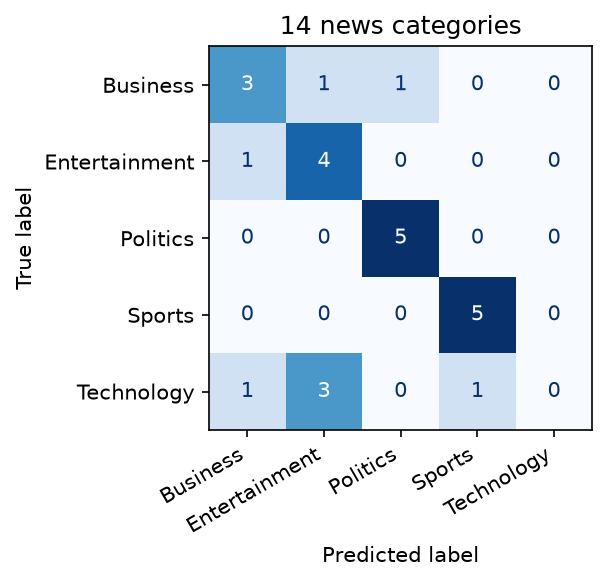

In [3]:
df = pd.read_csv(DATA / 'news.csv')
X, y = df.text.map(clean_text), df.label
assert not X.duplicated().any()
print('Headlines:', len(df), '| Categories:', sorted(y.unique()))
model = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)),
    LogisticRegression(solver='lbfgs', max_iter=2000, random_state=SEED))
metrics = evaluate(model, X, y, '14_news_categories')
examples = ['Team wins the football tournament final',
            'Software company releases a new artificial intelligence chip']
print('New headline predictions:', model.predict([clean_text(s) for s in examples]))

### Result and conclusion
Measured results: accuracy = 0.6800; macro_f1 = 0.6067; baseline_accuracy = 0.2000. Topic keywords are comparatively clear in this teaching corpus; production news can span multiple categories or change vocabulary.